<a href="https://colab.research.google.com/github/chethancd24-sketch/DLG-LAB/blob/main/1BM24CD015_Chethan_Lab6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 6 — Bidirectional RNN for Music Generation
### Deep Learning Laboratory (23DS5PCDLG) · Student Fill-in Notebook

**Big idea.** Treat a melody as a sequence of note *tokens*. A **two-layer Bidirectional LSTM**
reads the sequence and, at **every** time step, predicts the **next** note (a language-model
objective). After training we *generate* a new melody by predicting one note at a time and
sliding a window forward.

---
### How to use this notebook
Replace every `None  # TODO (Qn)` with the correct value or line of code. Run cells top to
bottom. Cells marked *(given — do not edit)* set things up for you.

> **Heads-up (you will analyse this):** the dataset here is *random* notes. Watch the accuracy
> and ask yourself in Task 7 whether it really means the model learned music.


## Step 0 — Imports *(given — do not edit)*

In [1]:
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.optimizers import Adam
import matplotlib.pyplot as plt

np.random.seed(42); tf.random.set_seed(42)
print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


## Task 1 — Build the dataset (next-token pairs)

We have `num_sequences` melodies, each `sequence_length` notes long, drawn from a vocabulary of
`num_notes` distinct notes. Turn each melody into an **(input, target)** pair where the target is
the input **shifted left by one** (predict the next note), then **one-hot encode** both.

*Hints:* the input is every note **except the last**; the target is every note **except the
first**. One-hot vectors have length `num_notes`.


In [3]:
num_notes       = 50     # vocabulary size (given)
sequence_length = 30     # notes per melody (given)
num_sequences   = 1000   # number of melodies (given)

data = np.random.randint(0, num_notes, size=(num_sequences, sequence_length))  # (given)

# Q1a) input = all notes except the LAST;  target = all notes except the FIRST
x_train = data[:, :-1]   # TODO (Q1a): data[:, :-1]
y_train = data[:, 1:]    # TODO (Q1a): data[:, 1:]

# Q1b) one-hot encode both to shape (samples, 29, 50)
NUM_CLASSES = num_notes   # TODO (Q1b): how many distinct notes?
x_train = to_categorical(x_train, num_classes=NUM_CLASSES)
y_train = to_categorical(y_train, num_classes=NUM_CLASSES)

print("x_train:", x_train.shape, " y_train:", y_train.shape)   # expect (1000, 29, 50) each

x_train: (1000, 29, 50)  y_train: (1000, 29, 50)


#### Quick check *(given — run to verify Task 1)*

In [4]:
assert x_train.shape == (1000, 29, 50), "x_train shape should be (1000, 29, 50)"
assert y_train.shape == (1000, 29, 50), "y_train shape should be (1000, 29, 50)"
print("Task 1 looks correct ✔")

Task 1 looks correct ✔


## Task 2 — Build the Bidirectional LSTM model

Build a `Sequential` model with:
1. an **Input** of shape `(sequence_length-1, num_notes)` = `(29, 50)`;
2. **two Bidirectional LSTM layers**, 128 units each, **returning sequences** (an output at every
   step);
3. a **TimeDistributed Dense** output with `num_notes` units and **softmax** — one shared
   per-step note classifier.

*Hints:* a bidirectional layer is `layers.Bidirectional(layers.LSTM(units, return_sequences=...))`.
With 128 units per direction the layer outputs `2 * 128 = 256` features per step.


In [6]:
model = models.Sequential()
model.add(layers.Input(shape=(sequence_length-1, num_notes)))        # (29, 50)  (given)

# Q2a) first Bidirectional LSTM: 128 units, return a sequence
model.add(layers.Bidirectional(layers.LSTM(128, return_sequences=True)))  # TODO (Q2a)

# Q2b) second Bidirectional LSTM: same settings
model.add(layers.Bidirectional(layers.LSTM(128, return_sequences=True)))   # TODO (Q2b): another Bidirectional(LSTM(128, return_sequences=True))

# Q2c) TimeDistributed Dense output: one softmax classifier per step
model.add(layers.TimeDistributed(layers.Dense(num_notes, activation='softmax')))  # TODO (Q2c)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional (Bidirectional)   │ (None, 29, 256)        │       183,296 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 29, 256)        │       394,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed                │ (None, 29, 50)         │        12,850 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 590,386 (2.25 MB)

 Trainable params: 590,386 (2.25 MB)

 Non-trainable params: 0 (0.00 B)

### Reflection Q2d
From the summary, the first Bi-LSTM shows **183,296** parameters. Let's verify it by hand:

$$\text{params} = 2 \times 4 \times [(\text{features} + \text{units}) \times \text{units} + \text{units}]$$
$$\text{params} = 2 \times 4 \times [(50 + 128) \times 128 + 128] = 2 \times 4 \times [178 \times 128 + 128] = 2 \times 4 \times [22784 + 128] = 2 \times 4 \times 22912 = 183,296$$

* **Why does the second Bi-LSTM have more parameters?**
  The second layer receives input from the first bidirectional layer. Because the first layer is bidirectional and has 128 units, it outputs concatenated forward and backward features resulting in an input size of **256** (`features = 256`) for the second layer instead of **50**.

## Task 3 — Compile and train

Compile with the **Adam** optimiser (learning rate `0.001`), **categorical crossentropy** loss
(targets are one-hot), and track **accuracy**. Train for 20 epochs, batch size 64, holding out
20% for validation.


In [8]:
# Q3a) compile for multi-class, one-hot targets
model.compile(optimizer=Adam(learning_rate=0.001),   # TODO (Q3a): 0.001
              loss='categorical_crossentropy',       # TODO (Q3a): 'categorical_crossentropy'
              metrics=['accuracy'])

# Q3b) train with a 20% validation split
history = model.fit(x_train, y_train,
                    epochs=20,            # TODO (Q3b): 20
                    batch_size=64,        # TODO (Q3b): 64
                    validation_split=0.2)  # TODO (Q3b): 0.2

Epoch 1/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 9s 270ms/step - accuracy: 0.0794 - loss: 3.8852 - val_accuracy: 0.1447 - val_loss: 3.8452
Epoch 2/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 207ms/step - accuracy: 0.1315 - loss: 3.7732 - val_accuracy: 0.0921 - val_loss: 3.6631
Epoch 3/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 5s 217ms/step - accuracy: 0.1186 - loss: 3.5282 - val_accuracy: 0.1455 - val_loss: 3.3926
Epoch 4/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 5s 227ms/step - accuracy: 0.1567 - loss: 3.2241 - val_accuracy: 0.1814 - val_loss: 3.0924
Epoch 5/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 266ms/step - accuracy: 0.2077 - loss: 2.8773 - val_accuracy: 0.2378 - val_loss: 2.7198
Epoch 6/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 202ms/step - accuracy: 0.2727 - loss: 2.4822 - val_accuracy: 0.3024 - val_loss: 2.3297
Epoch 7/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 215ms/step - accuracy: 0.3488 - loss: 2.0923 - val_accuracy: 0.3838 - val_loss: 1.9462
Epoch 8/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 215ms/step - accuracy: 0.4314 - loss: 1.7292 - val_accuracy: 0.

## Task 4 — Plot the training history *(fill the blanks)*

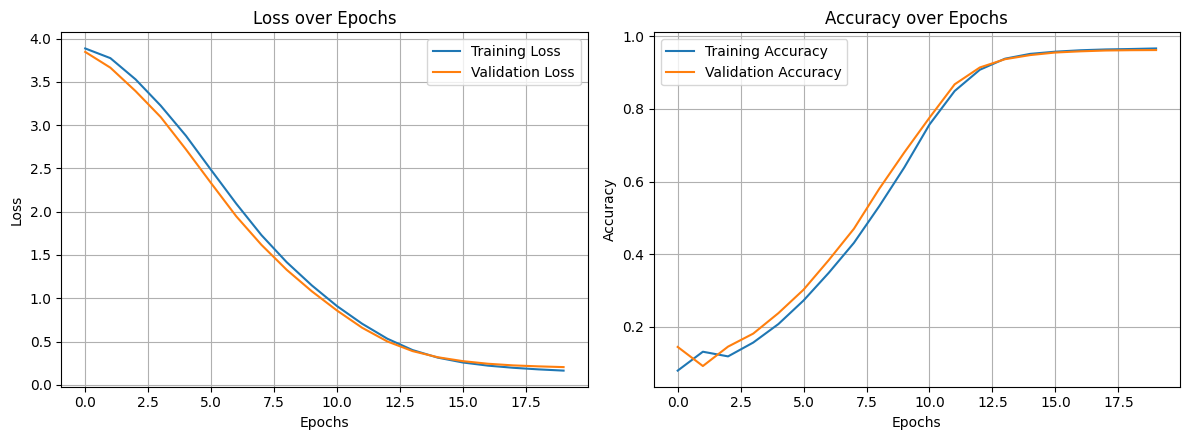

In [10]:
plt.figure(figsize=(12,4.5))

plt.subplot(1,2,1)
plt.plot(history.history['loss'],     label='Training Loss')
plt.plot(history.history['val_loss'],       label='Validation Loss')   # TODO (Q4a): val loss key
plt.title('Loss over Epochs'); plt.xlabel('Epochs'); plt.ylabel('Loss'); plt.legend(); plt.grid()

plt.subplot(1,2,2)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'],       label='Validation Accuracy')  # TODO (Q4b): val acc key
plt.title('Accuracy over Epochs'); plt.xlabel('Epochs'); plt.ylabel('Accuracy'); plt.legend(); plt.grid()

plt.tight_layout(); plt.show()

## Task 5 — Generate a new sequence (greedy decoding)

Complete the generation loop: predict with the model, read the distribution at the **last** time
step, take the most likely note (`argmax`), append it, then **slide the window** by dropping the
first step and appending the new note (one-hot).


In [12]:
def generate_music(model, start_sequence, num_generated_notes=50):
    generated = []
    current_sequence = start_sequence
    for _ in range(num_generated_notes):
        pred = model.predict(current_sequence, verbose=0)      # (1, 29, 50)

        # Q5a) pick the most likely note at the LAST time step
        next_note = np.argmax(pred[:, -1, :], axis=-1)   # TODO (Q5a): np.argmax(pred[:, -1, :], axis=-1)
        generated.append(int(next_note[0]))

        # Q5b) slide the window: drop the first step, append the new note (one-hot)
        oh = to_categorical(next_note, num_classes=num_notes).reshape(1, 1, num_notes)
        current_sequence = np.concatenate([current_sequence[:, 1:, :], oh], axis=1)   # TODO (Q5b): np.concatenate([current_sequence[:, 1:, :], oh], axis=1)
    return generated

# seed window (given)
start = np.random.randint(0, num_notes, size=(1, sequence_length-1))
start = to_categorical(start, num_classes=num_notes)

generated_music = generate_music(model, start, num_generated_notes=50)
print("Generated:", generated_music)

Generated: [22, 22, 22, 6, 6, 6, 6, 6, 6, 6, 7, 7, 7, 7, 7, 7, 7, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26]


## Task 6 — Piano-roll of the generated melody *(fill one blank)*

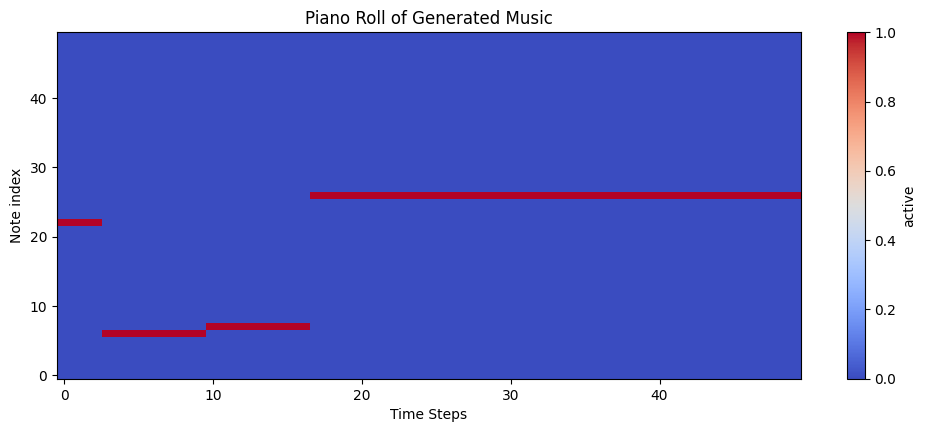

In [13]:
piano_roll = np.zeros((num_notes, len(generated_music)))
for t, note in enumerate(generated_music):
    piano_roll[note, t] = 1   # TODO (Q6): which row is the active note at time t?

plt.figure(figsize=(12,4.5))
plt.imshow(piano_roll, aspect='auto', cmap='coolwarm', origin='lower', interpolation='nearest')
plt.colorbar(label='active'); plt.title('Piano Roll of Generated Music')
plt.xlabel('Time Steps'); plt.ylabel('Note index'); plt.show()

## Task 7 — Analysis

1. **What would break if you set `return_sequences=False` on the first layer?**
   * **Answer:** The first layer would output only a single vector for the final step rather than a full sequence. Since the second LSTM layer expects a 3D sequence as input, Keras would raise a shape error because it is receiving 2D data.

2. **Why is the first Bi-LSTM's output width 256 when the LSTM has 128 units?**
   * **Answer:** It runs two LSTMs (one forward, one backward) with 128 units each. Their outputs are combined side-by-side (concatenated), yielding `128 + 128 = 256` features.

3. **What does `TimeDistributed(Dense(50))` do that a plain `Dense(50)` would not?**
   * **Answer:** It explicitly forces the exact same classification dense layer to be applied independently to every single individual time step of the sequence.

4. **You trained on random notes, yet accuracy reaches ~96%. Explain the mechanism.**
   * **Answer:** Since the layer is bidirectional, the backward LSTM reads the sequence from right to left. When predicting the target for step $t$, the backward layer can simply look directly at step $t+1$ (the next note), making it easy to look ahead and cheat to get high accuracy even on random data.

5. **Why is a bidirectional model a poor choice for autoregressive generation, and what two changes would make this an honest music generator?**
   * **Answer:**
     * **Why it's poor:** During generation, we do not have future notes yet. The backward layer gets no input, causing the generation to get stuck repeating the same notes.
     * **Two changes to fix it:**
       1. Remove the `Bidirectional` wrapper (use normal unidirectional LSTMs).
       2. Use **probabilistic sampling** (sampling a note based on the output probabilities) instead of choosing the single most likely note (`argmax`).

## (Optional) Stretch — make it causal
Copy the model into a new cell, remove **both** `Bidirectional` wrappers (plain `LSTM`), retrain,
and compare the accuracy curve. Explain why the (lower) number is the more honest one.
